# Creating a Daily Meal Plan Using AI

In [14]:
# Install the official OpenAI Python library.
# The -q flag suppresses installation output (quiet mode).
%pip install openai -q


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [15]:
# Verify the installed version of the openai package.
# Always confirm the version before running — the API changes between major releases.
%pip show openai

Name: openai
Version: 3.46.0
Summary: The official Python library for the openai API
Home-page: https://github.com/openai/openai-python
Author: 
Author-email: OpenAI <support@openai.com>
License-Expression: Apache-2.0
Location: /opt/miniconda3/lib/python3.13/site-packages
Requires: anyio, httpx2, jiter, pydantic, sniffio, typing-extensions
Required-by: 
Note: you may need to restart the kernel to use updated packages.


In [16]:
## Authentication
# Store your API key in a .env file (never hard-code secrets in a notebook):
# OPENAI_API_KEY="your-openai-api-key"   # dummy placeholder; put your real key in handbook/.env (template: handbook/.env.example)

# load_dotenv() reads the .env file and injects its values as environment variables.
# find_dotenv() searches the current and parent directories for the .env file.
# override=True ensures .env values take precedence over any pre-existing env vars.
from dotenv import load_dotenv, find_dotenv

load_dotenv(find_dotenv(), override=True)

True

In [17]:
def create_meals(ingredients, kcal=2000, exact_ingredients=False,
                 output_format='text', model='gpt-5.4',
                 system_role='You are a skilled cook with the expertise of a chef.',
                 temperature=1, extra=None):
    """Generate a daily meal plan using the ChatCompletion API.

    Parameters
    ----------
    ingredients     : comma-separated string of available ingredients
    kcal            : daily calorie target (default 2000)
    exact_ingredients: if True, restrict the model to only the supplied ingredients
    output_format   : 'text' or 'html' — controls how the model formats its answer
    model           : OpenAI chat model to use
    system_role     : sets the assistant's persona via the system message
    temperature     : controls randomness; 0 = deterministic, 2 = very creative
    extra           : optional free-text instruction appended as point 8
    """
    from openai import OpenAI
    client = OpenAI()

    # Ternary expression inside an f-string: choose the instruction based on the flag.
    # True  → strict mode: use only the listed ingredients.
    # False → creative mode: model may add complementary ingredients.
    prompt = f'''
    Create a healthy daily meal plan for breakfast, lunch, and dinner based on the following ingredients: ```{ingredients}```.
    Your output should be in the {output_format} format.
    Follow the instructions below carefully.
    ### Instructions:
    1. {'Use ONLY the provided ingredients with salt, pepper, and spices.' if exact_ingredients else 'Feel free to incorporate the provided ingredients as a base and add other ingredients if you consider them necessary to enhance the flavor, nutritional value, or overall appeal of the recipes.'}
    2. Specify the exact amount of each ingredient.
    3. Ensure that the total daily calorie intake is below {kcal}.
    4. For each meal, explain each recipe, step by step, in clear and simple sentences. Use bullet points or numbers to organize the steps.
    5. For each meal, specify the total number of calories and the number of servings.
    6. For each meal, provide a concise and descriptive title that summarizes the main ingredients and flavors. The title should also be a valid GPT Image prompt to generate an original image for the meal.
    7. For each recipe, indicate the prep, cook and total time.
    {'8. If possible the meals should be:' + extra if extra else '.'}
    9. Separate the recipes with 50 dashes (-).

    Before answering, make sure that you have followed the instructions listed above (points 1 to 9).
    The last line of your answer should be a string that contains ONLY the titles of the recipes and nothing more with a comma in between.
    Example of the last line of your answer:
    '\nBroccoli and Egg Scramble, Grilled Chicken and Vegetable, Baked Fish with Cabbage Slaw'.
    '''

    response = client.chat.completions.create(
        model=model,
        messages=[
            {'role': 'system', 'content': system_role},
            {'role': 'user', 'content': prompt}
        ],
        temperature=temperature
    )

    # Extract the text content from the first (and only) choice returned by the API.
    return response.choices[0].message.content

In [18]:
# Python ternary (conditional) expression — one-line if/else:
# value = expression1 if condition else expression2
a, b = 100, 20
value = 'a less than b' if a < b else 'a greater than b'
print(value)

# The same syntax is used inside the prompt f-string in create_meals().
exact_ingredients = True
'exact' if exact_ingredients else 'not exact'

a greater than b


'exact'

## Running the Program

In [19]:
foods = 'olive oil, whole grains, fruits and vegetables, nuts and seeds, fish, eggs, chicken breast, rice, honey'

# Call with all defaults (2000 kcal, text output, creative ingredients):
# output = create_meals(ingredients=foods)

# Override specific parameters using keyword arguments.
output = create_meals(
    ingredients=foods,
    model='gpt-5.4',
    output_format='text',
    extra='spicy in the mediterranean style',
    exact_ingredients=False
)

print(output)

Spicy Mediterranean Vegetable Egg Skillet with Whole-Grain Toast, rustic cast-iron pan with eggs, tomatoes, spinach, chili flakes, olive oil, herbs, whole-grain toast, bright natural light, appetizing healthy breakfast

**Servings:** 1  
**Prep time:** 10 minutes  
**Cook time:** 10 minutes  
**Total time:** 20 minutes  
**Total calories:** ~455 kcal

**Ingredients:**
- Olive oil: 2 tsp (10 ml)
- Eggs: 2 large
- Whole-grain bread: 2 slices (70 g)
- Spinach: 1 cup (30 g)
- Cherry tomatoes: 1 cup (150 g), halved
- Red onion: 1/4 small (25 g), thinly sliced
- Garlic: 1 clove (3 g), minced
- Feta cheese: 20 g
- Chili flakes: 1/4 tsp
- Ground cumin: 1/4 tsp
- Paprika: 1/2 tsp
- Fresh parsley: 1 tbsp (4 g), chopped
- Orange: 1 medium (130 g), on the side
- Salt: 1/8 tsp
- Black pepper: 1/8 tsp

**Step-by-step recipe:**
1. Heat 2 tsp olive oil in a small skillet over medium heat.
2. Add the sliced red onion and cook for 2 minutes until slightly soft.
3. Add the garlic, cherry tomatoes, paprik

In [20]:
# Uncomment to render the output as formatted HTML instead of plain text.
# Useful when output_format='html' is passed to create_meals().
# from IPython.display import display, HTML
# display(HTML(output))

## Generating Original Images for the Recipes Using GPT Image


In [21]:
# The model was instructed to put all recipe titles on the very last line.
# splitlines() splits the text into a list of lines; [-1] picks the last one.
titles = output.splitlines()[-1]

# Each title is separated by a comma — split into a list.
titles = titles.split(',')

# strip() removes leading/trailing spaces and stray quote characters.
titles = [t.strip(" '") for t in titles]

print(titles)

['Spicy Mediterranean Vegetable Egg Skillet with Whole-Grain Toast', 'rustic cast-iron pan with eggs', 'tomatoes', 'spinach', 'chili flakes', 'olive oil', 'herbs', 'whole-grain toast', 'bright natural light', 'appetizing healthy breakfast', 'Spicy Mediterranean Chicken Rice Bowl with Roasted Vegetables and Lemon-Herb Yogurt', 'grilled chicken breast over rice with roasted zucchini', 'bell pepper', 'cucumber', 'tomato', 'chili', 'olive oil', 'creamy yogurt sauce', 'vibrant mediterranean lunch bowl', 'Mediterranean Chili-Lemon Baked Fish with Herbed Rice and Honey-Roasted Carrots', 'flaky white fish fillet', 'golden rice', 'roasted carrots', 'olive oil glaze', 'herbs', 'lemon slices', 'warm spicy mediterranean dinner plating']


In [22]:
def create_and_save_image(title, model="gpt-image-2.5-flare", size="1024x1024", quality="medium", extra=""):
    """Generate a recipe image with GPT Image and save it as a PNG.

    Parameters
    ----------
    title   : recipe title used as the image prompt
    model   : GPT Image model available to your API project
    size    : image dimensions, e.g. "1024x1024"
    quality : "low", "medium", or "high" (model-dependent)
    extra   : optional visual direction appended to the prompt

    Returns
    -------
    str
        Path to the saved image file.
    """
    import base64
    import re
    from pathlib import Path
    from openai import OpenAI

    client = OpenAI()
    image_prompt = f"Photorealistic food photography of {title}. Appetizing, natural lighting. {extra}".strip()

    response = client.images.generate(
        model=model,
        prompt=image_prompt,
        size=size,
        quality=quality,
        output_format="png",
        n=1,
    )

    image_data = response.data[0].b64_json
    if not image_data:
        raise RuntimeError("The image API returned no base64 image data.")

    # Recipe titles may contain punctuation that is invalid in filenames.
    safe_title = re.sub(r"[^\w.-]+", "_", title, flags=re.UNICODE).strip("._") or "meal"
    image_path = Path(f"{safe_title}.png")
    image_path.write_bytes(base64.b64decode(image_data))
    return str(image_path)


Saved image to: rustic_cast-iron_pan_with_eggs.png


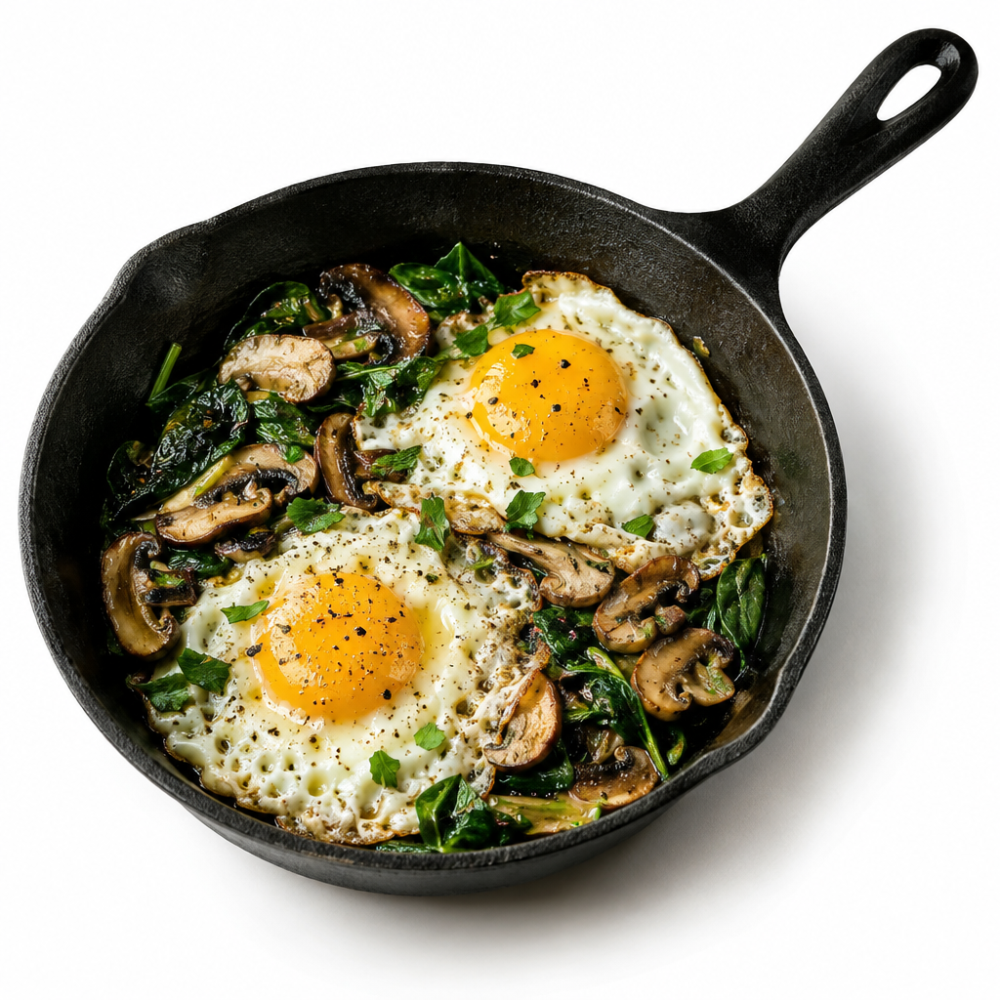

In [23]:
from PIL import Image
from IPython.display import display

# Generate and display one image first.
image_filename = create_and_save_image(titles[1], extra="clean white background")
print(f"Saved image to: {image_filename}")
display(Image.open(image_filename))


Saved image to: Spicy_Mediterranean_Vegetable_Egg_Skillet_with_Whole-Grain_Toast.png


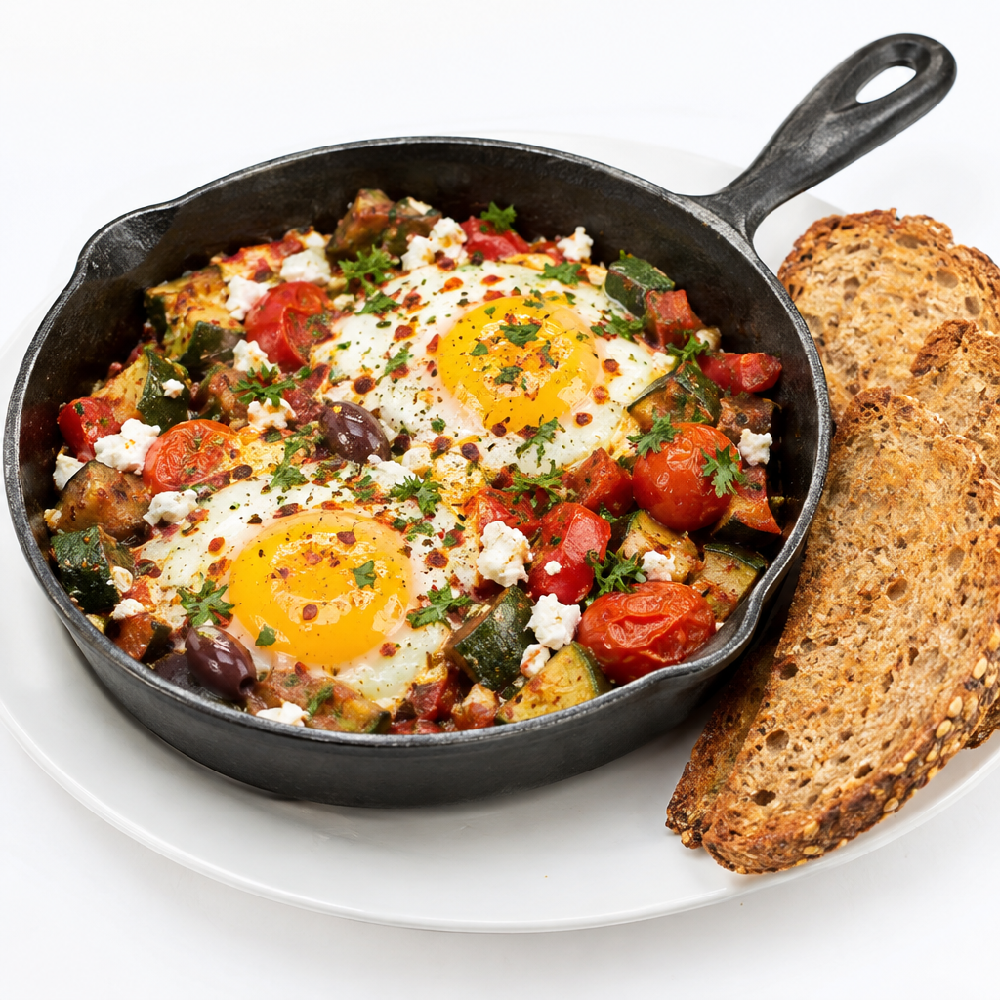

Saved image to: rustic_cast-iron_pan_with_eggs.png


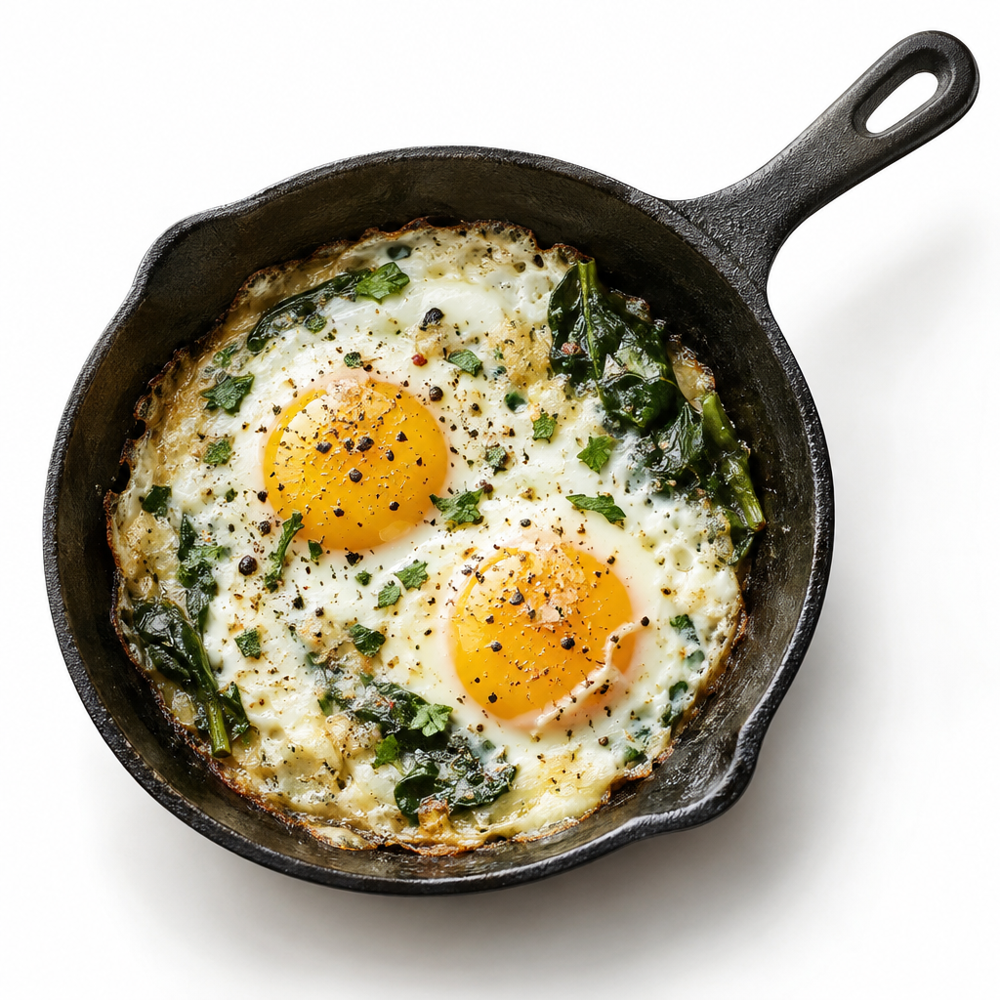

Saved image to: tomatoes.png


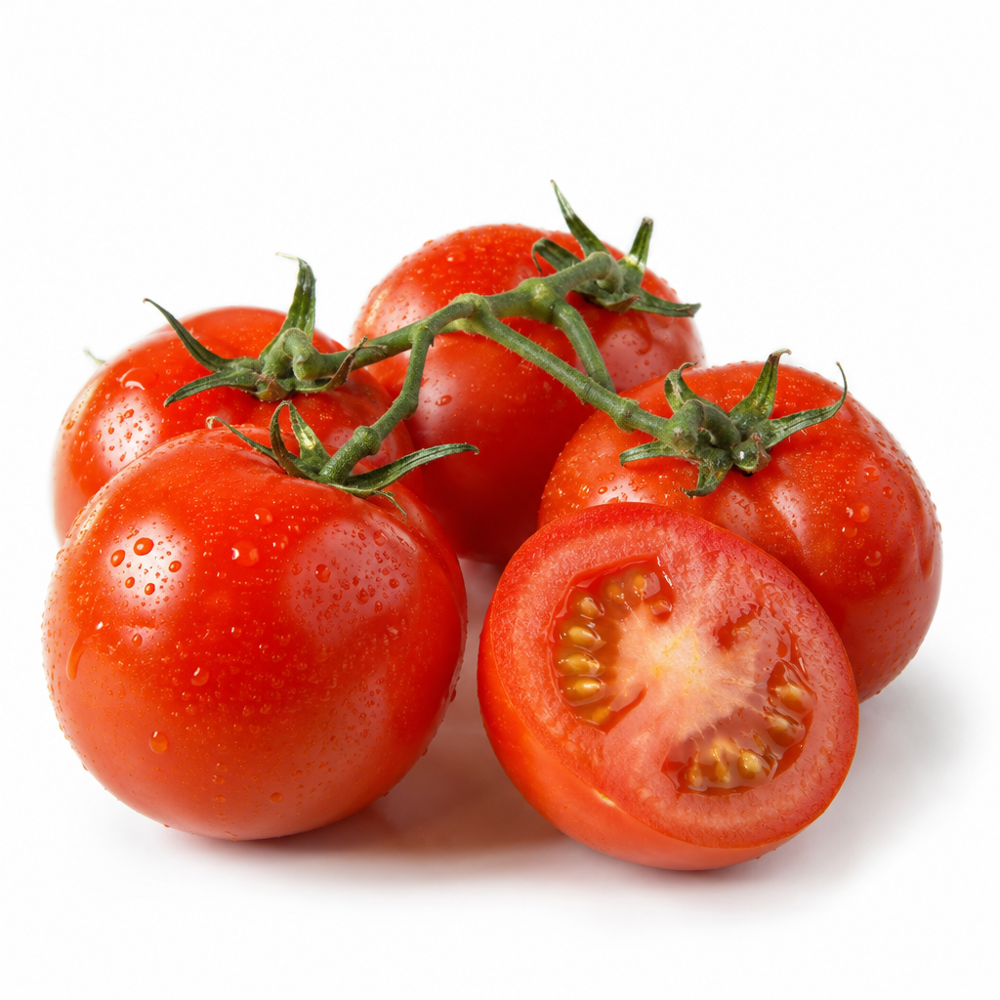

In [24]:
from PIL import Image
from IPython.display import display

# Generate and display one image per meal. Each call uses the image API and may incur a cost.
for title in titles[:3]:
    image_filename = create_and_save_image(title, extra="clean white background")
    print(f"Saved image to: {image_filename}")
    display(Image.open(image_filename))


# Narrate the Recipes Usint the TTS API

In [25]:
# The prompt instructed the model to separate recipes with 50 dashes.
# Splitting on that separator gives us a list: [breakfast, lunch, dinner, summary].
meals = output.split('-' * 50)
len(meals)

4

In [26]:
# Inspect the dinner recipe (index 2) to verify the structure before sending it to TTS.
print(meals[2])



Mediterranean Chili-Lemon Baked Fish with Herbed Rice and Honey-Roasted Carrots, flaky white fish fillet, golden rice, roasted carrots, olive oil glaze, herbs, lemon slices, warm spicy mediterranean dinner plating

**Servings:** 1  
**Prep time:** 15 minutes  
**Cook time:** 25 minutes  
**Total time:** 40 minutes  
**Total calories:** ~620 kcal

**Ingredients:**
- White fish fillet (such as cod or haddock): 170 g
- Cooked rice: 3/4 cup (150 g)
- Olive oil: 2 tsp (10 ml)
- Carrots: 200 g, cut into sticks
- Broccoli: 1 cup (90 g)
- Honey: 1 tsp (7 g)
- Lemon juice: 1 tbsp (15 ml)
- Lemon zest: 1/2 tsp
- Garlic: 1 clove (3 g), minced
- Paprika: 1/2 tsp
- Chili flakes: 1/4 tsp
- Ground cumin: 1/4 tsp
- Dried thyme: 1/2 tsp
- Fresh dill or parsley: 1 tbsp (4 g), chopped
- Almonds: 15 g, chopped
- Salt: 1/4 tsp
- Black pepper: 1/8 tsp

**Step-by-step recipe:**
1. Preheat the oven to 200°C / 400°F.
2. Place the carrot sticks on a baking tray. Toss them with 1 tsp olive oil, honey, a small 

In [27]:
# Ask the user which meal they want to hear; normalize input with lower() and strip().
meal = input("Enter meal's name (breakfast / lunch / dinner): ")
if meal.lower().strip() == 'breakfast':
    recipe = meals[0]
elif meal.lower().strip() == 'lunch':
    recipe = meals[1]
elif meal.lower().strip() == 'dinner':
    recipe = meals[2]
else:
    recipe = 'Invalid recipe!'

# The raw recipe text was written for reading, not speaking.
# We send it back to the model and ask it to adapt it for spoken delivery.
prompt = f'''I will provide a recipe that will be spoken aloud.
If necessary, you will adjust the recipe to make it more readable.
You can also add an introduction and summary, but you won't change the ingredients, instructions,
or other key elements of the recipe.
You respond ONLY with the adapted recipe and nothing else.
Recipe:```{recipe}```'''

from openai import OpenAI
client = OpenAI()

response = client.chat.completions.create(
    model='gpt-5.4',
    messages=[
        {'role': 'user', 'content': prompt}
    ]
)

spoken_recipe = response.choices[0].message.content

Enter meal's name (breakfast / lunch / dinner):  lunch


In [28]:
print(spoken_recipe)

Spicy Mediterranean Chicken Rice Bowl with Roasted Vegetables and Lemon-Herb Yogurt

A vibrant, satisfying Mediterranean-style lunch bowl with grilled chicken, roasted vegetables, fresh toppings, and a creamy lemon-herb yogurt sauce.

Servings: 1  
Prep time: 15 minutes  
Cook time: 25 minutes  
Total time: 40 minutes  
Total calories: about 675 calories

Ingredients:
- 150 grams chicken breast
- 3/4 cup, or 150 grams, cooked brown rice
- 2 teaspoons, or 10 milliliters, olive oil
- 1 cup, or 120 grams, zucchini, sliced
- 1 cup, or 120 grams, red bell pepper, sliced
- 1/2 cup, or 75 grams, cucumber, diced
- 1 medium tomato, or 120 grams, diced
- 1/4 small red onion, or 25 grams, sliced
- 80 grams plain Greek yogurt
- 1 tablespoon, or 15 milliliters, lemon juice
- 1 clove garlic, or 3 grams, minced
- 1/2 teaspoon ground coriander
- 1/2 teaspoon paprika
- 1/4 teaspoon chili flakes
- 1/2 teaspoon dried oregano
- 1 tablespoon, or 4 grams, fresh parsley, chopped
- 1 tablespoon, or 10 grams, 

In [29]:
def speak(recipe, filename):
    from openai import OpenAI
    client = OpenAI()

    # Recommended: with_streaming_response properly streams the audio to a file.
    with client.audio.speech.with_streaming_response.create(
        model='tts-1',
        voice='alloy',
        input=recipe
    ) as response:
        response.stream_to_file(filename)

    # Alternative: get the full response object and write bytes directly.
    # response = client.audio.speech.create(model='tts-1', voice='alloy', input=recipe)
    # Deprecated: response.stream_to_file(filename)  # DeprecationWarning: doesn't actually stream
    # with open(filename, 'wb') as f:
    #     f.write(response.content)

In [30]:
# Name the audio file after the chosen meal and convert the spoken recipe to speech.
filename = f'{meal}.mp3'
speak(spoken_recipe, filename)

In [31]:
import IPython

# Embed an interactive audio player directly in the notebook output.
IPython.display.Audio(filename)